# Lab 4: Logistic Regression and Multi-Layer Perceptron

**Goal:** Predict survival in the Titanic dataset using logistic regression and a neural network

This notebook uses passenger titles, cabin features and family information

Import the packages that will be used:

In [1]:
import os
import kagglehub

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier

Download the competition dataset:

In [2]:
path = kagglehub.competition_download('titanic-survival-2026')

path

'C:\\Users\\ricky\\.cache\\kagglehub\\competitions\\titanic-survival-2026'

# Training data

Read the training data from a CSV file, using the *id* column as index:

In [3]:
df = pd.read_csv(os.path.join(path, 'train.csv'), index_col='id')

train_ids, _ = train_test_split(df.index, test_size=0.2, random_state=0, stratify=df['survived'])

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,cabin,embarked,survived
id,,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,NaN,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,NaN,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,B80,C,1
4,3,"Shellard, Mr. Frederick William",male,NaN,0,0,C.A. 6212,15.1000,NaN,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,B96 B98,S,1
...,...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,NaN,S,0
1044,3,"Ryan, Mr. Patrick",male,NaN,0,0,371110,24.1500,NaN,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,NaN,S,1


# Data preparation

Identify the training rows so preprocessing statistics can be calculated without using validation data.

## Extracting information from names and cabins

Extract passenger titles, cabin numbers and deck levels before dropping the original text columns.

In [4]:
# Extract text between the comma and period
df["title"] = df["name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()



One-hot encode the extracted titles into candidate binary indicators.

In [5]:
# Create columns such as title_Mr, title_Master, title_Miss
df = pd.get_dummies(df, columns=["title"], prefix="title", dtype=int)



Group similar titles into seven indicators: `Miss`, `Mrs`, `Sir`, `Lady`, `Capt`, `Mr` and `Master`.

In [6]:
title_features = {
    "title_Miss": ["title_Miss", "title_Mlle", "title_Ms"],
    "title_Mrs": ["title_Mrs", "title_Mme"],
    "title_Sir": ["title_Sir", "title_Don"],
    "title_Lady": ["title_Lady", "title_Dona"],
    "title_Capt": ["title_Capt", "title_Col", "title_Major"],
    "title_Mr": ["title_Mr"],
    "title_Master": ["title_Master"],
}

for target, columns in title_features.items():
    existing = [column for column in columns if column in df.columns]
    df[target] = df[existing].max(axis=1) if existing else 0



Remove the other title indicators.

In [7]:
df.drop(
    columns=[
        column for column in df.columns
        if column.startswith("title_") and column not in title_features
    ],
    inplace=True
)



Extract the numeric part of the cabin identifier. Missing or unrecognized numbers become `-1`.

In [8]:
df['cabin_number'] = pd.to_numeric(df['cabin'].str.extract(r'^[A-G](\d+)', expand=False), errors='coerce').fillna(-1)



Encode the cabin deck as `A=1` through `G=7`, with `0` for unknown. This represents deck level, not physical distance.

In [9]:
df['deck_number'] = df['cabin'].str[0].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}).fillna(0).astype(int)



Drop the original `name`, `cabin` and `ticket` columns.

In [10]:
df.drop(['cabin', 'name', 'ticket'], axis=1, inplace=True)

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived,title_Capt,title_Lady,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,cabin_number,deck_number
id,,,,,,,,,,,,,,,,,
1,2,female,7.0,0,2,26.2500,S,1,0,0,0,1,0,0,0,-1.0,0
2,2,male,41.0,0,0,13.0000,S,0,0,0,0,0,0,0,0,-1.0,0
3,1,female,58.0,0,0,146.5208,C,1,0,0,0,1,0,0,0,80.0,2
4,3,male,NaN,0,0,15.1000,S,0,0,0,0,0,1,0,0,-1.0,0
5,1,female,36.0,1,2,120.0000,S,1,0,0,0,0,0,1,0,96.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,male,28.0,0,0,9.5000,S,0,0,0,0,0,1,0,0,-1.0,0
1044,3,male,NaN,0,0,24.1500,Q,0,0,0,0,0,1,0,0,-1.0,0
1045,3,male,3.0,4,2,31.3875,S,1,0,0,1,0,0,0,0,-1.0,0


## Missing values

Calculate the median age, most common departure port and mean fare using the training rows.

In [11]:
median_age    = df.loc[train_ids, 'age'].median()
mode_embarked = df.loc[train_ids, 'embarked'].mode()[0]
mean_fare     = df.loc[train_ids, 'fare'].mean()



Fill missing values with these training-derived statistics:

In [12]:
df['age']      = df['age'].fillna(median_age)
df['embarked'] = df['embarked'].fillna(mode_embarked)
df['fare']     = df['fare'].fillna(mean_fare)

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived,title_Capt,title_Lady,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,cabin_number,deck_number
id,,,,,,,,,,,,,,,,,
1,2,female,7.0,0,2,26.2500,S,1,0,0,0,1,0,0,0,-1.0,0
2,2,male,41.0,0,0,13.0000,S,0,0,0,0,0,0,0,0,-1.0,0
3,1,female,58.0,0,0,146.5208,C,1,0,0,0,1,0,0,0,80.0,2
4,3,male,28.0,0,0,15.1000,S,0,0,0,0,0,1,0,0,-1.0,0
5,1,female,36.0,1,2,120.0000,S,1,0,0,0,0,0,1,0,96.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,male,28.0,0,0,9.5000,S,0,0,0,0,0,1,0,0,-1.0,0
1044,3,male,28.0,0,0,24.1500,Q,0,0,0,0,0,1,0,0,-1.0,0
1045,3,male,3.0,4,2,31.3875,S,1,0,0,1,0,0,0,0,-1.0,0


Convert *gender* to a numeric feature:

In [13]:
gender_values = sorted(df['gender'].unique())

gender_mapping = {gender: i for i, gender in enumerate(gender_values)}

df['gender'] = df['gender'].map(gender_mapping)

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived,title_Capt,title_Lady,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,cabin_number,deck_number
id,,,,,,,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,S,1,0,0,0,1,0,0,0,-1.0,0
2,2,1,41.0,0,0,13.0000,S,0,0,0,0,0,0,0,0,-1.0,0
3,1,0,58.0,0,0,146.5208,C,1,0,0,0,1,0,0,0,80.0,2
4,3,1,28.0,0,0,15.1000,S,0,0,0,0,0,1,0,0,-1.0,0
5,1,0,36.0,1,2,120.0000,S,1,0,0,0,0,0,1,0,96.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,S,0,0,0,0,0,1,0,0,-1.0,0
1044,3,1,28.0,0,0,24.1500,Q,0,0,0,0,0,1,0,0,-1.0,0
1045,3,1,3.0,4,2,31.3875,S,1,0,0,1,0,0,0,0,-1.0,0


Encode `embarked` using one-hot encoding. Fit the encoder on the training rows:

In [14]:
encoder = OneHotEncoder(sparse_output=False, dtype=int)

encoder.fit(df.loc[train_ids, ['embarked']])

embarked_columns = encoder.get_feature_names_out()


Apply the encoder and remove the original `embarked` column:

In [15]:

df[embarked_columns] = encoder.transform(df[['embarked']])

df.drop('embarked', axis=1, inplace=True)

df

,pclass,gender,age,sibsp,parch,fare,survived,title_Capt,title_Lady,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,cabin_number,deck_number,embarked_C,embarked_Q,embarked_S
id,,,,,,,,,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,1,0,0,0,1,0,0,0,-1.0,0,0,0,1
2,2,1,41.0,0,0,13.0000,0,0,0,0,0,0,0,0,-1.0,0,0,0,1
3,1,0,58.0,0,0,146.5208,1,0,0,0,1,0,0,0,80.0,2,1,0,0
4,3,1,28.0,0,0,15.1000,0,0,0,0,0,1,0,0,-1.0,0,0,0,1
5,1,0,36.0,1,2,120.0000,1,0,0,0,0,0,1,0,96.0,2,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,0,0,0,0,0,1,0,0,-1.0,0,0,0,1
1044,3,1,28.0,0,0,24.1500,0,0,0,0,0,1,0,0,-1.0,0,0,1,0
1045,3,1,3.0,4,2,31.3875,1,0,0,1,0,0,0,0,-1.0,0,0,0,1


# Feature engineering

Create new features using family size, fare, passenger class, age and gender.

Calculate whether the passenger is travelling alone and the size of their family:

In [16]:
df['alone'] = ((df['sibsp'] + df['parch']) == 0).astype(int)

df['family'] = df['sibsp'] + df['parch'] + 1


Estimate fare per family member and combine passenger class with family size. The fare division is an approximation.

In [17]:
df['fare_per_family'] = df['fare'] / df['family']
df['pclass_x_family'] = df['pclass'] * df['family']

Recode gender as `-1` for female and `1` for male:

In [18]:
# make gender where is '1' stay '1', where is '0' become '-1'
df["gender"] = df["gender"].replace({0: -1})

Create `age_x_gender` and `adult_male`, which identifies male passengers aged 16 or older:

In [19]:
df['age_x_gender'] = df['age'] * df['gender']
df['adult_male'] = ((df['gender'] == 1) & (df['age'] >= 16)).astype(int)

df

,pclass,gender,age,sibsp,parch,fare,survived,title_Capt,title_Lady,title_Master,...,deck_number,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male
id,,,,,,,,,,,,,,,,,,,,,
1,2,-1,7.0,0,2,26.2500,1,0,0,0,...,0,0,0,1,0,3,8.750000,6,-7.0,0
2,2,1,41.0,0,0,13.0000,0,0,0,0,...,0,0,0,1,1,1,13.000000,2,41.0,1
3,1,-1,58.0,0,0,146.5208,1,0,0,0,...,2,1,0,0,1,1,146.520800,1,-58.0,0
4,3,1,28.0,0,0,15.1000,0,0,0,0,...,0,0,0,1,1,1,15.100000,3,28.0,1
5,1,-1,36.0,1,2,120.0000,1,0,0,0,...,2,0,0,1,0,4,30.000000,4,-36.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,0,0,0,0,...,0,0,0,1,1,1,9.500000,3,28.0,1
1044,3,1,28.0,0,0,24.1500,0,0,0,0,...,0,0,1,0,1,1,24.150000,3,28.0,1
1045,3,1,3.0,4,2,31.3875,1,0,0,1,...,0,0,0,1,0,7,4.483929,21,3.0,0


# Data scaling

Prepare a standard scaler for the numeric features:

In [20]:
scaler = StandardScaler()

scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Select the columns to standardize and fit the scaler on the training rows. Some title indicators are also standardized:

In [21]:
numeric_features = ['age', 'sibsp', 'parch', 'fare', 'family', 'age_x_gender', 'fare_per_family', 'pclass_x_family', 'cabin_number', 'deck_number', 'pclass', 'title_Mr', 'title_Master', 'title_Capt', 'title_Lady', 'title_Miss', 'title_Mrs', 'title_Sir']

scaler.fit(df.loc[train_ids, numeric_features])

scaler

StandardScaler()

Apply the fitted scaler to these columns:

In [22]:
df[numeric_features] = scaler.transform(df[numeric_features])

df

,pclass,gender,age,sibsp,parch,fare,survived,title_Capt,title_Lady,title_Master,...,deck_number,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male
id,,,,,,,,,,,,,,,,,,,,,
1,-0.319499,-1,-1.720714,-0.486398,1.943729,-0.125268,1,-0.084972,-0.048941,-0.215058,...,-0.483159,0,0,1,0,0.809926,-0.325027,0.424479,-0.542992,0
2,-0.319499,1,0.847518,-0.486398,-0.419236,-0.402056,0,-0.084972,-0.048941,-0.215058,...,-0.483159,0,0,1,1,-0.548607,-0.210918,-0.491804,1.002362,1
3,-1.508036,-1,2.131634,-0.486398,-0.419236,2.387152,1,-0.084972,-0.048941,-0.215058,...,0.813009,1,0,0,1,-0.548607,3.373995,-0.720875,-2.184930,0
4,0.869038,1,-0.134453,-0.486398,-0.419236,-0.358188,0,-0.084972,-0.048941,-0.215058,...,-0.483159,0,0,1,1,-0.548607,-0.154535,-0.262734,0.583829,1
5,-1.508036,-1,0.469837,0.587785,1.943729,1.833141,1,-0.084972,-0.048941,-0.215058,...,0.813009,0,0,1,0,1.489193,0.245517,-0.033663,-1.476643,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,0.869038,1,-0.134453,-0.486398,-0.419236,-0.475170,0,-0.084972,-0.048941,-0.215058,...,-0.483159,0,0,1,1,-0.548607,-0.304890,-0.262734,0.583829,1
1044,0.869038,1,-0.134453,-0.486398,-0.419236,-0.169136,0,-0.084972,-0.048941,-0.215058,...,-0.483159,0,1,0,1,-0.548607,0.088450,-0.262734,0.583829,1
1045,0.869038,1,-2.022858,3.810333,1.943729,-0.017947,1,-0.084972,-0.048941,4.649906,...,-0.483159,0,0,1,0,3.526993,-0.439567,3.860541,-0.221043,0


# Data splitting

Select `survived` as the target and 15 features for training the models:

In [23]:
target_column = 'survived'

feature_columns = ['gender', 'age', 'fare', 'family', 'embarked_C', 'embarked_Q', 'embarked_S', 'title_Mr', 'title_Master', 'title_Miss', 'title_Mrs', 'cabin_number', 'deck_number', 'pclass', 'fare_per_family']

feature_columns

['gender',
 'age',
 'fare',
 'family',
 'embarked_C',
 'embarked_Q',
 'embarked_S',
 'title_Mr',
 'title_Master',
 'title_Miss',
 'title_Mrs',
 'cabin_number',
 'deck_number',
 'pclass',
 'fare_per_family']

Split the training data into a training set and a validation set:

In [24]:
df_train, df_valid = train_test_split(df,
                                      test_size=0.2,
                                      random_state=0,
                                      stratify=df[target_column])

print(df_train.shape, df_valid.shape)

(837, 25) (210, 25)


The use of *stratify* above ensures that the training set and the validation set have (approximately) the same class distribution:

In [25]:
pd.concat([df_train[target_column].value_counts(normalize=True),
           df_valid[target_column].value_counts(normalize=True)],
          axis=1, keys=['train', 'val']).style.format('{:.1%}')

,train,val
survived,,
0,61.8%,61.9%
1,38.2%,38.1%


# Logistic regression

Prepare a logistic regression model:

In [26]:
model = LogisticRegression(max_iter=1000, random_state=0)

model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

Fit the logistic regression model to the training set:

In [27]:
model.fit(df_train[feature_columns], df_train[target_column])

model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

Retrieve the weights and bias of the model:

In [28]:
weights = model.coef_[0]
bias = model.intercept_

print(weights)
print(bias)

[-0.9025051  -0.29767442  0.17781199 -0.63729855  0.41142027 -0.19174659
 -0.26438048 -0.2807452   0.49650835  0.18204674  0.40002178  0.05942602
  0.20770888 -0.66852259 -0.13629701]
[-0.24726933]


Note that this model has the following number of parameters:

In [29]:
total = weights.size + bias.size

print(f'Total: {total} parameters')

Total: 16 parameters


Plot the feature coefficients. Positive coefficients increase the predicted log-odds of survival, while negative coefficients decrease them:

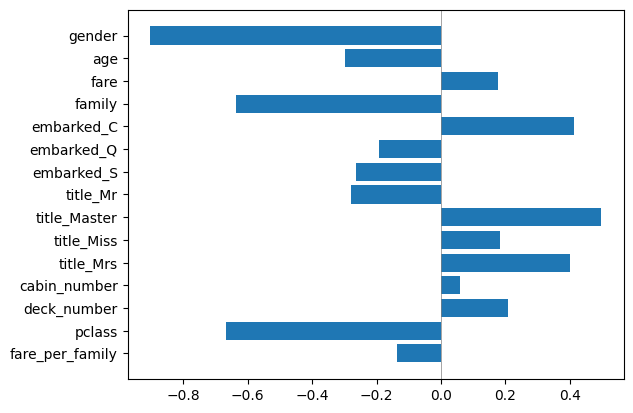

In [30]:
plt.barh(feature_columns, weights)

plt.gca().invert_yaxis()

plt.axvline(0, color='gray', linewidth=0.5)

Interpret the signs and relative sizes of the coefficients.

# Model evaluation

Make predictions with logistic regression on the validation set:

In [31]:
predict_column = 'prediction'

df_valid[predict_column] = model.predict(df_valid[feature_columns])

df_valid

,pclass,gender,age,sibsp,parch,fare,survived,title_Capt,title_Lady,title_Master,...,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male,prediction
id,,,,,,,,,,,,,,,,,,,,,
531,0.869038,-1,0.092156,0.587785,0.762247,-0.244861,1,-0.084972,-0.048941,-0.215058,...,0,0,1,0,0.809926,-0.376264,1.111691,-1.315669,0,1
937,0.869038,-1,-1.871786,-0.486398,-0.419236,-0.413023,1,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.225014,-0.262734,-0.478602,0,1
836,-1.508036,1,1.527344,0.587785,-0.419236,1.549563,0,-0.084972,-0.048941,-0.215058,...,1,0,0,0,0.130659,0.868751,-0.491804,1.292116,1,0
884,0.869038,-1,0.469837,-0.486398,1.943729,-0.341476,1,-0.084972,-0.048941,-0.215058,...,0,0,1,0,0.809926,-0.417656,1.111691,-1.476643,0,1
690,0.869038,1,-0.587670,-0.486398,-0.419236,-0.522172,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.365300,-0.262734,0.390660,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,-0.319499,1,0.771982,-0.486398,-0.419236,-0.402056,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.210918,-0.491804,0.970167,1,0
314,0.869038,1,0.620910,-0.486398,-0.419236,-0.508682,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.347961,-0.262734,0.905778,1,0
944,0.869038,1,-0.134453,-0.486398,-0.419236,-0.511727,1,-0.084972,-0.048941,-0.215058,...,0,1,0,1,-0.548607,-0.351876,-0.262734,0.583829,1,0


Check the metrics on the validation set:

In [32]:
accuracy  =  accuracy_score(df_valid[target_column], df_valid[predict_column])
precision = precision_score(df_valid[target_column], df_valid[predict_column])
recall    =    recall_score(df_valid[target_column], df_valid[predict_column])
f1        =        f1_score(df_valid[target_column], df_valid[predict_column])

print(f'accuracy : { accuracy:.3f}')
print(f'precision: {precision:.3f}')
print(f'recall   : {   recall:.3f}')
print(f'f1 score : {       f1:.3f}')

accuracy : 0.814
precision: 0.753
recall   : 0.762
f1 score : 0.758


Plot the confusion matrix for true vs. predicted labels on the validation set:

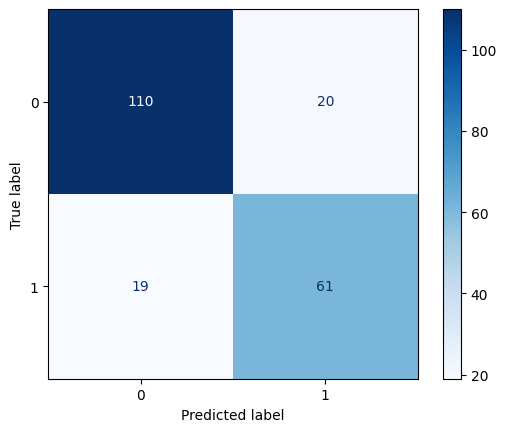

In [33]:
ConfusionMatrixDisplay.from_predictions(df_valid[target_column],
                                        df_valid[predict_column],
                                        cmap='Blues')

# Neural network

Use an MLP with eight neurons in one hidden layer, `tanh` activation, the `lbfgs` solver and `alpha=10` regularization:

In [34]:
model = MLPClassifier(hidden_layer_sizes=(8,),
                      activation='tanh',
                      solver='lbfgs',
                      alpha=10,
                      max_iter=1000,
                      random_state=0)

model

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(8,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'lbfgs'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",10
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


Fit the multi-layer perceptron (MLP) to the training set:

In [35]:
model.fit(df_train[feature_columns], df_train[target_column])

model

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(8,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'lbfgs'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",10
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


Display the training loss. With `lbfgs`, the final loss is shown instead of a loss curve:

In [36]:
if hasattr(model, 'loss_curve_'):
    plt.plot(model.loss_curve_)
    plt.xlabel('iteration')
    plt.ylabel('training loss')
else:
    print(f'Final training loss: {model.loss_:.4f}')

Final training loss: 0.4345


Count the weights and biases in each layer. This network has 137 trainable parameters:

In [37]:
total = 0

for i, (weights, bias) in enumerate(zip(model.coefs_, model.intercepts_)):
    print(f'Layer {i}:')
    print(f'* weights: {weights.shape}')
    print(f'* bias: {bias.shape}')

    total += weights.size + bias.size

print(f'Total: {total} parameters')

Layer 0:
* weights: (15, 8)
* bias: (8,)
Layer 1:
* weights: (8, 1)
* bias: (1,)
Total: 137 parameters


Compare the number of parameters with logistic regression.

# Model evaluation

Make predictions with the MLP on the same validation set:

In [38]:
df_valid[predict_column] = model.predict(df_valid[feature_columns])

df_valid

,pclass,gender,age,sibsp,parch,fare,survived,title_Capt,title_Lady,title_Master,...,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male,prediction
id,,,,,,,,,,,,,,,,,,,,,
531,0.869038,-1,0.092156,0.587785,0.762247,-0.244861,1,-0.084972,-0.048941,-0.215058,...,0,0,1,0,0.809926,-0.376264,1.111691,-1.315669,0,0
937,0.869038,-1,-1.871786,-0.486398,-0.419236,-0.413023,1,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.225014,-0.262734,-0.478602,0,1
836,-1.508036,1,1.527344,0.587785,-0.419236,1.549563,0,-0.084972,-0.048941,-0.215058,...,1,0,0,0,0.130659,0.868751,-0.491804,1.292116,1,0
884,0.869038,-1,0.469837,-0.486398,1.943729,-0.341476,1,-0.084972,-0.048941,-0.215058,...,0,0,1,0,0.809926,-0.417656,1.111691,-1.476643,0,0
690,0.869038,1,-0.587670,-0.486398,-0.419236,-0.522172,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.365300,-0.262734,0.390660,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,-0.319499,1,0.771982,-0.486398,-0.419236,-0.402056,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.210918,-0.491804,0.970167,1,0
314,0.869038,1,0.620910,-0.486398,-0.419236,-0.508682,0,-0.084972,-0.048941,-0.215058,...,0,0,1,1,-0.548607,-0.347961,-0.262734,0.905778,1,0
944,0.869038,1,-0.134453,-0.486398,-0.419236,-0.511727,1,-0.084972,-0.048941,-0.215058,...,0,1,0,1,-0.548607,-0.351876,-0.262734,0.583829,1,0


Calculate accuracy, precision, recall, F1 and macro F1 for the MLP:

In [39]:
accuracy  =  accuracy_score(df_valid[target_column], df_valid[predict_column])
precision = precision_score(df_valid[target_column], df_valid[predict_column])
recall    =    recall_score(df_valid[target_column], df_valid[predict_column])
f1        =        f1_score(df_valid[target_column], df_valid[predict_column])
f1_m        =        f1_score(df_valid[target_column], df_valid[predict_column], average='macro')

print(f'accuracy : { accuracy:.3f}')
print(f'precision: {precision:.3f}')
print(f'recall   : {   recall:.3f}')
print(f'f1 score : {       f1:.3f}')
print(f'f1 macro : {       f1_m:.3f}')

accuracy : 0.819
precision: 0.792
recall   : 0.713
f1 score : 0.750
f1 macro : 0.804


Plot the confusion matrix for true vs. predicted labels on the validation set:

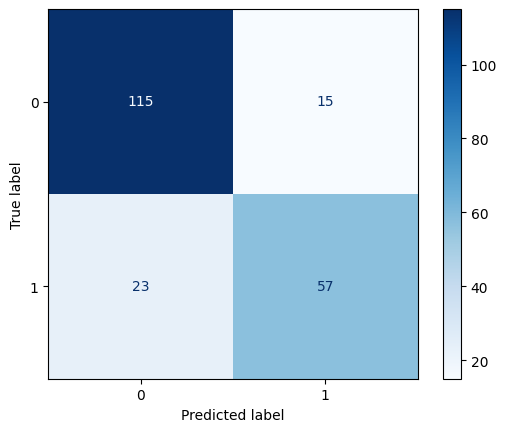

In [40]:
ConfusionMatrixDisplay.from_predictions(df_valid[target_column],
                                        df_valid[predict_column],
                                        cmap='Blues')

Compare the validation results of logistic regression and the MLP.

# Test data

Read the test data from a CSV file, using the *id* column as index:

In [41]:
df_test = pd.read_csv(os.path.join(path, 'test.csv'), index_col='id')

df_test

,pclass,name,gender,age,sibsp,parch,ticket,fare,cabin,embarked
id,,,,,,,,,,
1048,3,"Turkula, Mrs. (Hedwig)",female,63.0,0,0,4134,9.5875,NaN,S
1049,2,"Bryhl, Miss. Dagmar Jenny Ingeborg",female,20.0,1,0,236853,26.0000,NaN,S
1050,2,"Knight, Mr. Robert J",male,NaN,0,0,239855,0.0000,NaN,S
1051,2,"Sjostedt, Mr. Ernst Adolf",male,59.0,0,0,237442,13.5000,NaN,S
1052,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.0,0,1,392091,9.3500,NaN,S
...,...,...,...,...,...,...,...,...,...,...
1305,3,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
1306,1,"Kenyon, Mrs. Frederick R (Marion)",female,NaN,1,0,17464,51.8625,D21,S
1307,2,"Smith, Miss. Marion Elsie",female,40.0,0,0,31418,13.0000,NaN,S


## Test preprocessing

Extract the same title and cabin features from the test data:

In [42]:
# Extract text between the comma and period
df_test["title"] = df_test["name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()



One-hot encode the extracted test titles:

In [43]:
# Create columns such as title_Mr, title_Master, title_Miss
df_test = pd.get_dummies(df_test, columns=["title"], prefix="title", dtype=int)



Create the same seven title indicators as in training:

In [44]:
for target, columns in title_features.items():
    existing = [column for column in columns if column in df_test.columns]
    df_test[target] = df_test[existing].max(axis=1) if existing else 0



Remove any extra title columns:

In [45]:
df_test.drop(
    columns=[
        column for column in df_test.columns
        if column.startswith("title_") and column not in title_features
    ],
    inplace=True
)

df_test.drop(
    columns=[col for col in df_test.columns if col.startswith("title_") and col not in df.columns],
    inplace=True
)



Extract `cabin_number` using `-1` for missing or unrecognized numbers:

In [46]:
df_test['cabin_number'] = pd.to_numeric(df_test['cabin'].str.extract(r'^[A-G](\d+)', expand=False), errors='coerce').fillna(-1)



Create `deck_number` with the same mapping:

In [47]:
df_test['deck_number'] = df_test['cabin'].str[0].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}).fillna(0).astype(int)



Drop the original `cabin`, `name` and `ticket` columns:

In [48]:
df_test.drop(['cabin', 'name', 'ticket'], axis=1, inplace=True)

df_test

,pclass,gender,age,sibsp,parch,fare,embarked,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,title_Lady,title_Capt,cabin_number,deck_number
id,,,,,,,,,,,,,,,,
1048,3,female,63.0,0,0,9.5875,S,0,0,0,1,0,0,0,-1.0,0
1049,2,female,20.0,1,0,26.0000,S,0,1,0,0,0,0,0,-1.0,0
1050,2,male,NaN,0,0,0.0000,S,0,0,1,0,0,0,0,-1.0,0
1051,2,male,59.0,0,0,13.5000,S,0,0,1,0,0,0,0,-1.0,0
1052,3,female,18.0,0,1,9.3500,S,0,0,0,1,0,0,0,-1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,male,NaN,0,0,8.0500,S,0,0,1,0,0,0,0,-1.0,0
1306,1,female,NaN,1,0,51.8625,S,0,0,0,1,0,0,0,21.0,4
1307,2,female,40.0,0,0,13.0000,S,0,1,0,0,0,0,0,-1.0,0


Fill missing values using the statistics calculated from the training data:

In [49]:
df_test['age']      = df_test['age'].fillna(median_age)
df_test['embarked'] = df_test['embarked'].fillna(mode_embarked)
df_test['fare']     = df_test['fare'].fillna(mean_fare)

df_test

,pclass,gender,age,sibsp,parch,fare,embarked,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,title_Lady,title_Capt,cabin_number,deck_number
id,,,,,,,,,,,,,,,,
1048,3,female,63.0,0,0,9.5875,S,0,0,0,1,0,0,0,-1.0,0
1049,2,female,20.0,1,0,26.0000,S,0,1,0,0,0,0,0,-1.0,0
1050,2,male,28.0,0,0,0.0000,S,0,0,1,0,0,0,0,-1.0,0
1051,2,male,59.0,0,0,13.5000,S,0,0,1,0,0,0,0,-1.0,0
1052,3,female,18.0,0,1,9.3500,S,0,0,0,1,0,0,0,-1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,male,28.0,0,0,8.0500,S,0,0,1,0,0,0,0,-1.0,0
1306,1,female,28.0,1,0,51.8625,S,0,0,0,1,0,0,0,21.0,4
1307,2,female,40.0,0,0,13.0000,S,0,1,0,0,0,0,0,-1.0,0


Apply the gender mapping and the previously fitted encoder for `embarked`:

In [50]:
df_test['gender'] = df_test['gender'].map(gender_mapping)

df_test[embarked_columns] = encoder.transform(df_test[['embarked']])

df_test.drop('embarked', axis=1, inplace=True)

df_test

,pclass,gender,age,sibsp,parch,fare,title_Master,title_Miss,title_Mr,title_Mrs,title_Sir,title_Lady,title_Capt,cabin_number,deck_number,embarked_C,embarked_Q,embarked_S
id,,,,,,,,,,,,,,,,,,
1048,3,0,63.0,0,0,9.5875,0,0,0,1,0,0,0,-1.0,0,0,0,1
1049,2,0,20.0,1,0,26.0000,0,1,0,0,0,0,0,-1.0,0,0,0,1
1050,2,1,28.0,0,0,0.0000,0,0,1,0,0,0,0,-1.0,0,0,0,1
1051,2,1,59.0,0,0,13.5000,0,0,1,0,0,0,0,-1.0,0,0,0,1
1052,3,0,18.0,0,1,9.3500,0,0,0,1,0,0,0,-1.0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,1,28.0,0,0,8.0500,0,0,1,0,0,0,0,-1.0,0,0,0,1
1306,1,0,28.0,1,0,51.8625,0,0,0,1,0,0,0,21.0,4,0,0,1
1307,2,0,40.0,0,0,13.0000,0,1,0,0,0,0,0,-1.0,0,0,0,1


Calculate `alone` and `family` for the test data:

In [51]:
df_test['alone'] = ((df_test['sibsp'] + df_test['parch']) == 0).astype(int)

df_test['family'] = df_test['sibsp'] + df_test['parch'] + 1


Create `fare_per_family` and `pclass_x_family`:

In [52]:
df_test['fare_per_family'] = df_test['fare'] / df_test['family']
df_test['pclass_x_family'] = df_test['pclass'] * df_test['family']




Recode gender as `-1` or `1`:

In [53]:
# make gender where is '1' stay '1', where is '0' become '-1'
df_test["gender"] = df_test["gender"].replace({0: -1})



Create `age_x_gender` and `adult_male` with the same 16-year cutoff:

In [54]:
df_test['age_x_gender'] = df_test['age'] * df_test['gender']
df_test['adult_male'] = ((df_test['gender'] == 1) & (df_test['age'] >= 16)).astype(int)

df_test

,pclass,gender,age,sibsp,parch,fare,title_Master,title_Miss,title_Mr,title_Mrs,...,deck_number,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male
id,,,,,,,,,,,,,,,,,,,,,
1048,3,-1,63.0,0,0,9.5875,0,0,0,1,...,0,0,0,1,1,1,9.58750,3,-63.0,0
1049,2,-1,20.0,1,0,26.0000,0,1,0,0,...,0,0,0,1,0,2,13.00000,4,-20.0,0
1050,2,1,28.0,0,0,0.0000,0,0,1,0,...,0,0,0,1,1,1,0.00000,2,28.0,1
1051,2,1,59.0,0,0,13.5000,0,0,1,0,...,0,0,0,1,1,1,13.50000,2,59.0,1
1052,3,-1,18.0,0,1,9.3500,0,0,0,1,...,0,0,0,1,0,2,4.67500,6,-18.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,1,28.0,0,0,8.0500,0,0,1,0,...,0,0,0,1,1,1,8.05000,3,28.0,1
1306,1,-1,28.0,1,0,51.8625,0,0,0,1,...,4,0,0,1,0,2,25.93125,2,-28.0,0
1307,2,-1,40.0,0,0,13.0000,0,1,0,0,...,0,0,0,1,1,1,13.00000,2,-40.0,0


Standardize the test columns using the scaler fitted on the training data:

In [55]:
#df_test[numeric_features] = scaler.transform(df_test[numeric_features])
test_numeric = df_test.reindex(columns=numeric_features, fill_value=0)
df_test[numeric_features] = scaler.transform(test_numeric)

df_test

,pclass,gender,age,sibsp,parch,fare,title_Master,title_Miss,title_Mr,title_Mrs,...,deck_number,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male
id,,,,,,,,,,,,,,,,,,,,,
1048,0.869038,-1,2.509315,-0.486398,-0.419236,-0.473342,-0.215058,-0.489898,-1.191249,2.386629,...,-0.483159,0,0,1,1,-0.548607,-0.302541,-0.262734,-2.345905,0
1049,-0.319499,-1,-0.738743,0.587785,-0.419236,-0.130490,-0.215058,2.041241,-1.191249,-0.419001,...,-0.483159,0,0,1,0,0.130659,-0.210918,-0.033663,-0.961525,0
1050,-0.319499,1,-0.134453,-0.486398,-0.419236,-0.673622,-0.215058,-0.489898,0.839455,-0.419001,...,-0.483159,0,0,1,1,-0.548607,-0.559956,-0.491804,0.583829,1
1051,-0.319499,1,2.207171,-0.486398,-0.419236,-0.391612,-0.215058,-0.489898,0.839455,-0.419001,...,-0.483159,0,0,1,1,-0.548607,-0.197493,-0.491804,1.581870,1
1052,0.869038,-1,-0.889815,-0.486398,0.762247,-0.478304,-0.215058,-0.489898,-1.191249,2.386629,...,-0.483159,0,0,1,0,0.130659,-0.434437,0.424479,-0.897135,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,0.869038,1,-0.134453,-0.486398,-0.419236,-0.505460,-0.215058,-0.489898,0.839455,-0.419001,...,-0.483159,0,0,1,1,-0.548607,-0.343821,-0.262734,0.583829,1
1306,-1.508036,-1,-0.134453,0.587785,-0.419236,0.409769,-0.215058,-0.489898,-1.191249,2.386629,...,2.109177,0,0,1,0,0.130659,0.136274,-0.491804,-1.219084,0
1307,-0.319499,-1,0.771982,-0.486398,-0.419236,-0.402056,-0.215058,2.041241,-1.191249,-0.419001,...,-0.483159,0,0,1,1,-0.548607,-0.210918,-0.491804,-1.605423,0


Select the same features and make predictions with the MLP:

In [56]:
X_test = df_test.reindex(columns=feature_columns, fill_value=0)
df_test[target_column] = model.predict(X_test)

df_test

,pclass,gender,age,sibsp,parch,fare,title_Master,title_Miss,title_Mr,title_Mrs,...,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,pclass_x_family,age_x_gender,adult_male,survived
id,,,,,,,,,,,,,,,,,,,,,
1048,0.869038,-1,2.509315,-0.486398,-0.419236,-0.473342,-0.215058,-0.489898,-1.191249,2.386629,...,0,0,1,1,-0.548607,-0.302541,-0.262734,-2.345905,0,0
1049,-0.319499,-1,-0.738743,0.587785,-0.419236,-0.130490,-0.215058,2.041241,-1.191249,-0.419001,...,0,0,1,0,0.130659,-0.210918,-0.033663,-0.961525,0,1
1050,-0.319499,1,-0.134453,-0.486398,-0.419236,-0.673622,-0.215058,-0.489898,0.839455,-0.419001,...,0,0,1,1,-0.548607,-0.559956,-0.491804,0.583829,1,0
1051,-0.319499,1,2.207171,-0.486398,-0.419236,-0.391612,-0.215058,-0.489898,0.839455,-0.419001,...,0,0,1,1,-0.548607,-0.197493,-0.491804,1.581870,1,0
1052,0.869038,-1,-0.889815,-0.486398,0.762247,-0.478304,-0.215058,-0.489898,-1.191249,2.386629,...,0,0,1,0,0.130659,-0.434437,0.424479,-0.897135,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,0.869038,1,-0.134453,-0.486398,-0.419236,-0.505460,-0.215058,-0.489898,0.839455,-0.419001,...,0,0,1,1,-0.548607,-0.343821,-0.262734,0.583829,1,0
1306,-1.508036,-1,-0.134453,0.587785,-0.419236,0.409769,-0.215058,-0.489898,-1.191249,2.386629,...,0,0,1,0,0.130659,0.136274,-0.491804,-1.219084,0,1
1307,-0.319499,-1,0.771982,-0.486398,-0.419236,-0.402056,-0.215058,2.041241,-1.191249,-0.419001,...,0,0,1,1,-0.548607,-0.210918,-0.491804,-1.605423,0,1


Prepare a submission:

In [57]:
df_submission = df_test[target_column].to_frame()

df_submission

,survived
id,
1048,0
1049,1
1050,0
1051,0
1052,1
...,...
1305,0
1306,1
1307,1


Save the submission file:

In [58]:
df_submission.to_csv('submission.csv')

Submit this file to the competition, and check your score on the leaderboard!🍀

**Leaderboard Score:** 0.715 (underperforming decision trees for this specific test set)